# MMA3001 — RetinaNet Four-Class Object Detection

## Aim
Evaluate the previously trained RetinaNet ResNet50-FPN V2 checkpoint for detecting and localising four pork rasher packaging defects.

## Defect Classes
1. loose-meat
2. packaging-error
3. twisted-meat
4. unsealed

The wrinkle class was excluded from the final four-class experiment because it was represented by only six independent source images in the original dataset.

## Objectives
1. Verify the four-class dataset and annotations.
2. Load the previously selected best RetinaNet checkpoint without retraining.
3. Analyse the saved 15-epoch training history.
4. Evaluate overall and per-class validation performance using COCO-style metrics.
5. Compare raw and normalised confusion matrices at different confidence thresholds.
6. Analyse Micro-F1, Macro-F1 and per-class recall.
7. Evaluate computational performance for the final model comparison.

## Evaluation Protocol
The training and validation results are reproduced from the saved experiment artifacts. Confidence thresholds are evaluated using the validation split only. The test split is reserved for the final three-model comparison in Notebook 07.

Reusable dataset loading, checkpoint management, evaluation, metric calculations and plotting are imported from the `mma3001` Python package maintained in GitHub.

In [1]:

# Install the dependencies needed to evaluate the saved RetinaNet model.
%pip install -q torchmetrics pycocotools pandas matplotlib pyyaml pillow


In [2]:

# Configure Google Drive storage and the shared GitHub Python package.

import gc
import os
import subprocess
import sys
import time

from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch

from IPython.display import display
from google.colab import drive
from torch.utils.data import DataLoader
from torchmetrics.detection.mean_ap import MeanAveragePrecision

REPO_URL = "https://github.com/daniellawjmcc/MMA3001_Project.git"
REPO_ROOT = Path("/content/MMA3001_Project_repo")

DRIVE_ROOT = Path("/content/gdrive_new")
DEFAULT_PROJECT_ROOT = DRIVE_ROOT / "MyDrive" / "MMA3001_Project"

if not DEFAULT_PROJECT_ROOT.is_dir():
    drive.mount(str(DRIVE_ROOT))

if not REPO_ROOT.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO_ROOT), "pull", "--ff-only"],
        check=True,
    )

source_path = str(REPO_ROOT / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)

from mma3001.config import (
    FOUR_CLASS_NAMES,
    SEED,
    find_project_root,
    get_dataset_path,
    get_run_path,
    get_checkpoint_path,
    set_seed,
)

from mma3001.dataset import (
    YoloDetectionDataset,
    detection_collate_fn,
    load_class_names,
)

from mma3001.evaluation import (
    evaluate_thresholds,
    select_best_threshold,
    correct_detections_table,
    per_class_recall_table,
)

from mma3001.plotting import (
    plot_training_history,
    plot_confusion_matrices,
    plot_threshold_metrics,
    plot_per_class_recall,
    show_saved_figure,
)

from mma3001.models import (
    load_experiment_model,
    count_parameters,
)

set_seed(SEED)

project_root = find_project_root(
    os.environ.get(
        "MMA3001_PROJECT_ROOT",
        str(DEFAULT_PROJECT_ROOT),
    )
)

dataset_root = get_dataset_path(
    project_root,
    four_class=True,
)

run_dir = get_run_path(
    project_root,
    "retinanet_4class",
)

best_model_path = get_checkpoint_path(
    project_root,
    "retinanet_4class",
)

CLASS_NAMES = list(FOUR_CLASS_NAMES)
NUM_CLASSES = len(CLASS_NAMES)
MATRIX_LABELS = CLASS_NAMES + ["background"]

class_mapping = load_class_names(dataset_root)

assert [
    class_mapping[index]
    for index in range(NUM_CLASSES)
] == CLASS_NAMES

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Save regenerated figures separately from the original training run.
output_dir = Path("/content/notebook05_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Dataset:", dataset_root)
print("Training run:", run_dir)
print("Best checkpoint:", best_model_path)
print("Class mapping:", class_mapping)
print("Device:", device)
print("New output directory:", output_dir)


Dataset: /content/gdrive_new/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class
Training run: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_4class
Best checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_4class/best.pt
Class mapping: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed'}
Device: cuda
New output directory: /content/notebook05_outputs


## 1. Dataset Verification

The final four-class dataset is inspected without regenerating, copying or modifying the underlying images and annotations.

YOLO bounding boxes are converted into pixel-coordinate boxes by the shared `YoloDetectionDataset` class. Class labels are shifted from 0–3 to 1–4 to follow the label convention used when training this RetinaNet checkpoint.

Class distributions and representative annotations are inspected to identify class imbalance and verify the data-loading procedure.

In [3]:

# Load the existing dataset without copying or regenerating files.

train_dataset = YoloDetectionDataset(
    dataset_root,
    split="train",
    label_offset=1,
)

valid_dataset = YoloDetectionDataset(
    dataset_root,
    split="valid",
    label_offset=1,
)

test_dataset = YoloDetectionDataset(
    dataset_root,
    split="test",
    label_offset=1,
)

dataset_counts = {
    "Train": len(train_dataset),
    "Validation": len(valid_dataset),
    "Test": len(test_dataset),
}

print("DATASET IMAGE COUNTS")
display(
    pd.DataFrame([
        {"Split": name, "Images": count}
        for name, count in dataset_counts.items()
    ])
)

assert len(train_dataset) == 3138
assert len(valid_dataset) == 120
assert len(test_dataset) == 80

# Count the existing annotations without loading every image.
distribution_rows = []

for split_name, dataset in [
    ("Train", train_dataset),
    ("Validation", valid_dataset),
    ("Test", test_dataset),
]:
    counts = Counter()

    for image_path in dataset.image_paths:
        label_path = (
            dataset.labels_dir / f"{image_path.stem}.txt"
        )

        if not label_path.is_file():
            continue

        for line in label_path.read_text(
            encoding="utf-8"
        ).splitlines():
            values = line.split()

            if not values:
                continue

            class_id = int(values[0])
            counts[class_id] += 1

    for class_id, class_name in enumerate(CLASS_NAMES):
        distribution_rows.append({
            "Split": split_name,
            "Class": class_name,
            "Annotations": counts[class_id],
        })

distribution_df = pd.DataFrame(distribution_rows)

print("\nDEFECT ANNOTATION DISTRIBUTION")
display(distribution_df)

# Create the validation loader used for saved-checkpoint inference.
valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    collate_fn=detection_collate_fn,
)

print("\nValidation batches:", len(valid_loader))


DATASET IMAGE COUNTS


,Split,Images
0,Train,3138
1,Validation,120
2,Test,80



DEFECT ANNOTATION DISTRIBUTION


,Split,Class,Annotations
0,Train,loose-meat,60
1,Train,packaging-error,1616
2,Train,twisted-meat,70
3,Train,unsealed,994
4,Validation,loose-meat,3
5,Validation,packaging-error,34
6,Validation,twisted-meat,3
7,Validation,unsealed,81
8,Test,loose-meat,3
9,Test,packaging-error,23



Validation batches: 30


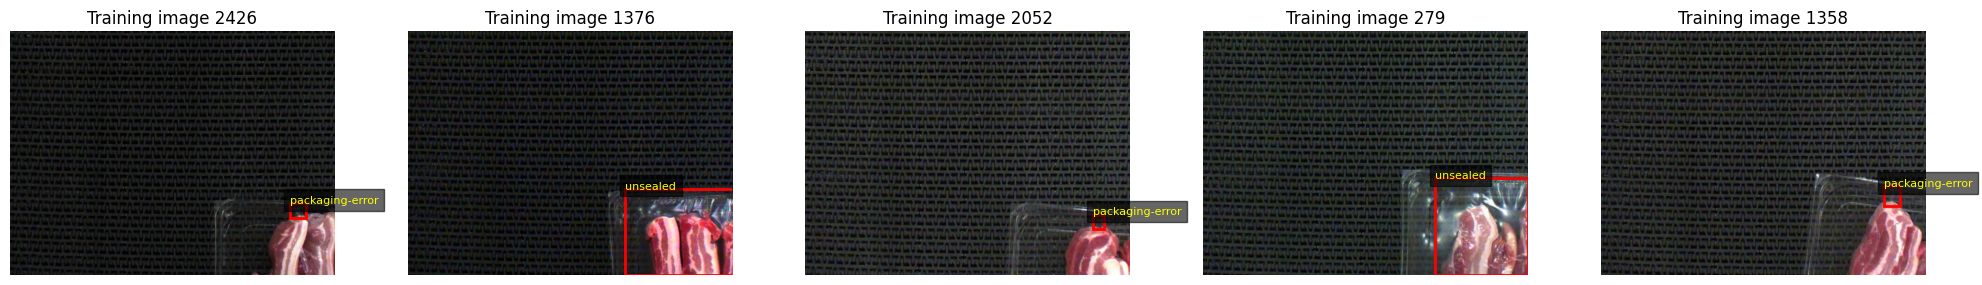

In [4]:

# Display five reproducibly selected training samples.

rng = np.random.default_rng(SEED)

sample_indices = rng.choice(
    len(train_dataset),
    size=5,
    replace=False,
)

fig, axes = plt.subplots(
    1,
    len(sample_indices),
    figsize=(20, 5),
)

for ax, index in zip(axes, sample_indices):
    image, target = train_dataset[int(index)]

    ax.imshow(
        image.permute(1, 2, 0).numpy()
    )

    for box, label in zip(
        target["boxes"],
        target["labels"],
    ):
        x1, y1, x2, y2 = box.tolist()
        class_name = CLASS_NAMES[int(label) - 1]

        rectangle = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )

        ax.add_patch(rectangle)

        ax.text(
            x1,
            y1,
            class_name,
            fontsize=8,
            color="yellow",
            bbox={
                "facecolor": "black",
                "alpha": 0.6,
            },
        )

    ax.set_title(f"Training image {int(index)}")
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)


## 2. Saved RetinaNet Checkpoint

The original RetinaNet ResNet50-FPN V2 model was trained for 15 epochs using a COCO-pretrained backbone and a modified classification head.

The best checkpoint was selected according to validation mAP@50:95. This notebook reloads the existing checkpoint without repeating model training.

The original inference preprocessing is restored using a minimum and maximum image size of 640 pixels.

## 3. Training Performance Analysis

The saved `training_history.csv` is used to examine training loss and validation mAP across all 15 epochs. The historical results are displayed directly from the completed experiment rather than reconstructed from a new training run.

In [5]:

# Load the original saved checkpoint using the shared model loader.

retinanet = load_experiment_model(
    project_root=project_root,
    run_name="retinanet_4class",
    device=device,
)

# Restore the exact image-size settings from the training notebook.
retinanet.transform.min_size = (640,)
retinanet.transform.max_size = 640

# Restore the original postprocessing configuration.
retinanet.score_thresh = 0.05
retinanet.nms_thresh = 0.50
retinanet.detections_per_img = 100

retinanet.eval()

# Read checkpoint metadata without restoring the optimiser or training.
checkpoint_metadata = torch.load(
    best_model_path,
    map_location="cpu",
    weights_only=True,
)

saved_epoch = int(checkpoint_metadata["epoch"])
saved_map = float(checkpoint_metadata["val_map"])

print("RetinaNet checkpoint loaded.")
print("Selected epoch:", saved_epoch)
print("Saved validation mAP@50:95:", round(saved_map, 4))
print("Image preprocessing:", retinanet.transform.min_size,
      retinanet.transform.max_size)
print("Internal confidence threshold:", retinanet.score_thresh)
print("NMS threshold:", retinanet.nms_thresh)
print("Maximum detections:", retinanet.detections_per_img)

assert saved_epoch == 13
assert abs(saved_map - 0.2465) < 0.001

del checkpoint_metadata


RetinaNet checkpoint loaded.
Selected epoch: 13
Saved validation mAP@50:95: 0.2465
Image preprocessing: (640,) 640
Internal confidence threshold: 0.05
NMS threshold: 0.5
Maximum detections: 100


ORIGINAL TRAINING HISTORY


,Epoch,Train_Loss,Val_mAP50,Val_mAP50_95,Epoch_Seconds
0,1,0.8028,0.2016,0.1283,159.9506
1,2,0.5396,0.2425,0.1498,154.7055
2,3,0.4764,0.2534,0.1366,154.9889
3,4,0.3652,0.2575,0.1556,152.3259
4,5,0.2960,0.3173,0.1838,154.7817
5,6,0.2168,0.2651,0.1537,155.3439
6,7,0.1734,0.2692,0.1583,153.7219
7,8,0.1501,0.3088,0.1737,152.9863
8,9,0.1339,0.2809,0.1618,152.1868
9,10,0.1193,0.3622,0.2168,152.2310


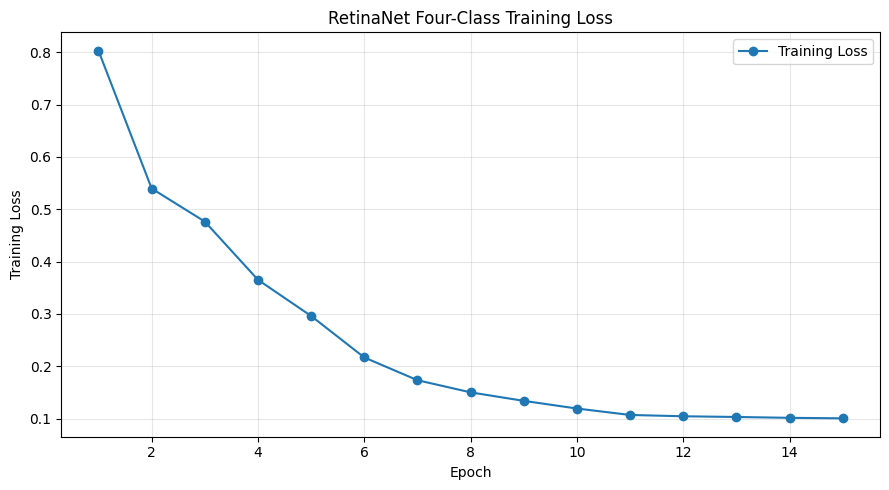

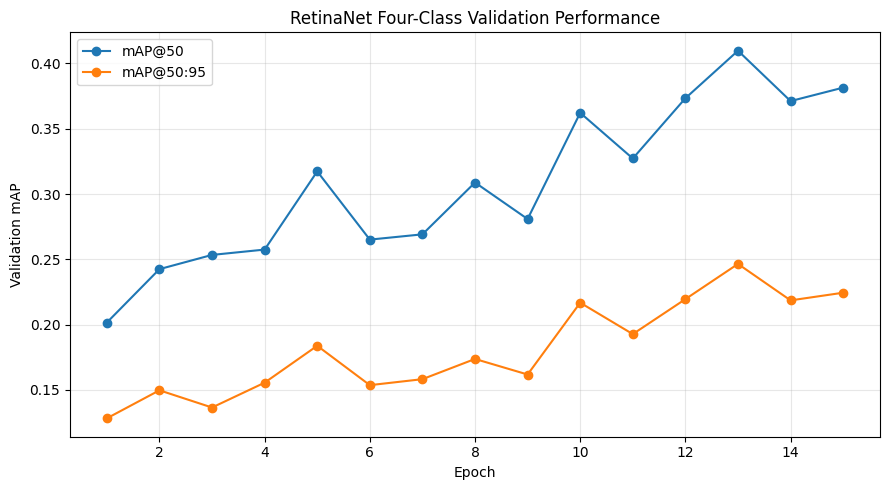

Best recorded epoch: 13
Best historical mAP@50:95: 0.2465
Sum of recorded epoch durations (seconds): 2311.92


In [6]:

# Read the original saved 15-epoch training history.

history_path = run_dir / "training_history.csv"

if not history_path.is_file():
    raise FileNotFoundError(
        f"Original training history missing: {history_path}"
    )

history_df = pd.read_csv(history_path)
history_df.columns = history_df.columns.str.strip()

print("ORIGINAL TRAINING HISTORY")
display(history_df.round(4))

assert len(history_df) == 15

# Plot recorded training loss using the shared plotting module.
loss_figure = plot_training_history(
    history_df,
    metric_columns={
        "Train_Loss": "Training Loss",
    },
    epoch_column="Epoch",
    title="RetinaNet Four-Class Training Loss",
    ylabel="Training Loss",
)

loss_figure.savefig(
    output_dir / "training_loss.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(loss_figure)

# Plot recorded validation AP for all 15 epochs.
map_figure = plot_training_history(
    history_df,
    metric_columns={
        "Val_mAP50": "mAP@50",
        "Val_mAP50_95": "mAP@50:95",
    },
    epoch_column="Epoch",
    title="RetinaNet Four-Class Validation Performance",
    ylabel="Validation mAP",
)

map_figure.savefig(
    output_dir / "validation_map.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(map_figure)

best_epoch_row = history_df.loc[
    history_df["Val_mAP50_95"].idxmax()
]

historical_training_seconds = float(
    history_df["Epoch_Seconds"].sum()
)

print("Best recorded epoch:", int(best_epoch_row["Epoch"]))
print(
    "Best historical mAP@50:95:",
    round(float(best_epoch_row["Val_mAP50_95"]), 4),
)
print(
    "Sum of recorded epoch durations (seconds):",
    round(historical_training_seconds, 2),
)

assert int(best_epoch_row["Epoch"]) == saved_epoch


## 4. Validation Performance

The saved best checkpoint is evaluated against the complete four-class validation split using COCO-style object detection metrics.

Overall mAP@50, mAP@50:95, mAP@75 and mAR@100 are calculated using TorchMetrics. Per-class average precision is examined to identify performance differences caused by defect appearance and class imbalance.

The evaluation uses the original trained model and the shared dataset loader. No training or checkpoint modification occurs.

In [7]:

# Collect all validation predictions once for AP and threshold analysis.

@torch.inference_mode()
def collect_predictions(model, data_loader, inference_device):
    """Collect RetinaNet predictions and ground-truth annotations.

    The model performs inference on each validation batch without
    updating its parameters. The resulting tensors are transferred
    to the CPU for subsequent evaluation.

    Args:
        model: Loaded RetinaNet ResNet50-FPN V2 detection model.
        data_loader: DataLoader containing images and ground-truth
            detection targets.
        inference_device: PyTorch device used to execute inference.

    Returns:
        Tuple containing two lists:
            - Prediction dictionaries with boxes, scores and labels.
            - Ground-truth dictionaries with boxes and labels.
        Both lists follow the original validation image order.
    """

    model.eval()

    predictions = []
    targets = []

    for images, batch_targets in data_loader:
        images_on_device = [
            image.to(inference_device)
            for image in images
        ]

        batch_predictions = model(images_on_device)

        for prediction, target in zip(
            batch_predictions,
            batch_targets,
        ):
            predictions.append({
                "boxes": prediction["boxes"].detach().cpu(),
                "scores": prediction["scores"].detach().cpu(),
                "labels": prediction["labels"].detach().cpu().long(),
            })

            targets.append({
                "boxes": target["boxes"].detach().cpu(),
                "labels": target["labels"].detach().cpu().long(),
            })

    return predictions, targets


predictions_all, targets_all = collect_predictions(
    retinanet,
    valid_loader,
    device,
)

assert len(predictions_all) == 120
assert len(targets_all) == 120

print("Prediction images:", len(predictions_all))
print("Ground-truth images:", len(targets_all))

print(
    "Total predictions:",
    sum(len(record["scores"]) for record in predictions_all),
)

# Preserve raw model predictions for the COCO-style AP calculation.
# The fixed-threshold confusion matrices use only labels 1–4.
predictions_for_matching = []

reserved_predictions = 0

for prediction in predictions_all:
    valid = (
        (prediction["labels"] >= 1)
        & (prediction["labels"] <= NUM_CLASSES)
    )

    reserved_predictions += int((~valid).sum())

    predictions_for_matching.append({
        "boxes": prediction["boxes"][valid],
        "scores": prediction["scores"][valid],
        "labels": prediction["labels"][valid],
    })

print(
    "Reserved-class predictions excluded from confusion matrices:",
    reserved_predictions,
)


Prediction images: 120
Ground-truth images: 120
Total predictions: 1442
Reserved-class predictions excluded from confusion matrices: 0


In [8]:

# Calculate COCO-style validation metrics from original model predictions.

metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

metric.update(
    predictions_all,
    targets_all,
)

validation_results = metric.compute()

overall_ap_df = pd.DataFrame([{
    "mAP@50": float(validation_results["map_50"]),
    "mAP@50:95": float(validation_results["map"]),
    "mAP@75": float(validation_results["map_75"]),
    "mAR@100": float(validation_results["mar_100"]),
}])

class_ap_mapping = {
    int(class_id): float(ap)
    for class_id, ap in zip(
        validation_results["classes"],
        validation_results["map_per_class"],
    )
}

per_class_ap_df = pd.DataFrame([
    {
        "Class": name,
        "mAP@50:95": class_ap_mapping.get(class_id, np.nan),
    }
    for class_id, name in enumerate(CLASS_NAMES, start=1)
])

print("FOUR-CLASS RETINANET VALIDATION RESULTS")
display(overall_ap_df.round(4))

print("\nPER-CLASS AVERAGE PRECISION")
display(per_class_ap_df.round(4))

print("\nORIGINAL CHECKPOINT VALIDATION REPRODUCIBILITY")

print(
    "Original mAP@50:95: 0.2465",
    "| Recomputed:",
    round(float(validation_results["map"]), 4),
)

print(
    "Original mAP@50: 0.4098",
    "| Recomputed:",
    round(float(validation_results["map_50"]), 4),
)

# Use a small tolerance for library-version numerical differences.
map_match = abs(
    float(validation_results["map"]) - 0.2465
) <= 0.005

map50_match = abs(
    float(validation_results["map_50"]) - 0.4098
) <= 0.005

print("mAP@50:95 within tolerance:", map_match)
print("mAP@50 within tolerance:", map50_match)

if not (map_match and map50_match):
    print(
        "WARNING: Validation AP differs from the original run. "
        "Check the checkpoint, preprocessing and library versions."
    )


FOUR-CLASS RETINANET VALIDATION RESULTS


,mAP@50,mAP@50:95,mAP@75,mAR@100
0,0.4098,0.2465,0.3139,0.3895



PER-CLASS AVERAGE PRECISION


,Class,mAP@50:95
0,loose-meat,0.1727
1,packaging-error,0.0545
2,twisted-meat,0.2020
3,unsealed,0.5569



ORIGINAL CHECKPOINT VALIDATION REPRODUCIBILITY
Original mAP@50:95: 0.2465 | Recomputed: 0.2465
Original mAP@50: 0.4098 | Recomputed: 0.4098
mAP@50:95 within tolerance: True
mAP@50 within tolerance: True


## 5. Confidence-Threshold Evaluation

The saved validation predictions are evaluated at confidence thresholds of 0.10, 0.25, 0.50, 0.70 and 0.849, using a detection IoU threshold of 0.50.

The shared evaluation functions perform descending-confidence, one-to-one IoU matching. Confusion matrices use predicted categories as rows, true categories as columns, and background as the final row and column.

Micro-F1 measures overall detection performance, whereas Macro-F1 gives equal weight to each of the four defect classes.

## 6. Confusion Matrix Analysis

Raw and normalised confusion matrices are displayed for all five confidence thresholds. The results show correctly detected objects, class-confusion errors, unmatched detections and missed objects.

Column normalisation is used to examine the distribution of predictions within each actual defect class.

FIVE-THRESHOLD RETINANET COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,Micro-F1,Macro-F1
0,0.100,91,498,30,0.1545,0.7521,0.2563,0.2123
1,0.250,87,73,34,0.5438,0.7190,0.6192,0.2873
2,0.500,82,32,39,0.7193,0.6777,0.6979,0.3016
3,0.700,77,21,44,0.7857,0.6364,0.7032,0.2854
4,0.849,72,12,49,0.8571,0.5950,0.7024,0.2736



CORRECT DETECTIONS BY CLASS


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,1,18,0,72
0.250,0,15,0,72
0.500,0,11,0,71
0.700,0,7,0,70
0.849,0,5,0,67



PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,0.3333,0.5294,0.0,0.8889
0.250,0.0000,0.4412,0.0,0.8889
0.500,0.0000,0.3235,0.0,0.8765
0.700,0.0000,0.2059,0.0,0.8642
0.849,0.0000,0.1471,0.0,0.8272


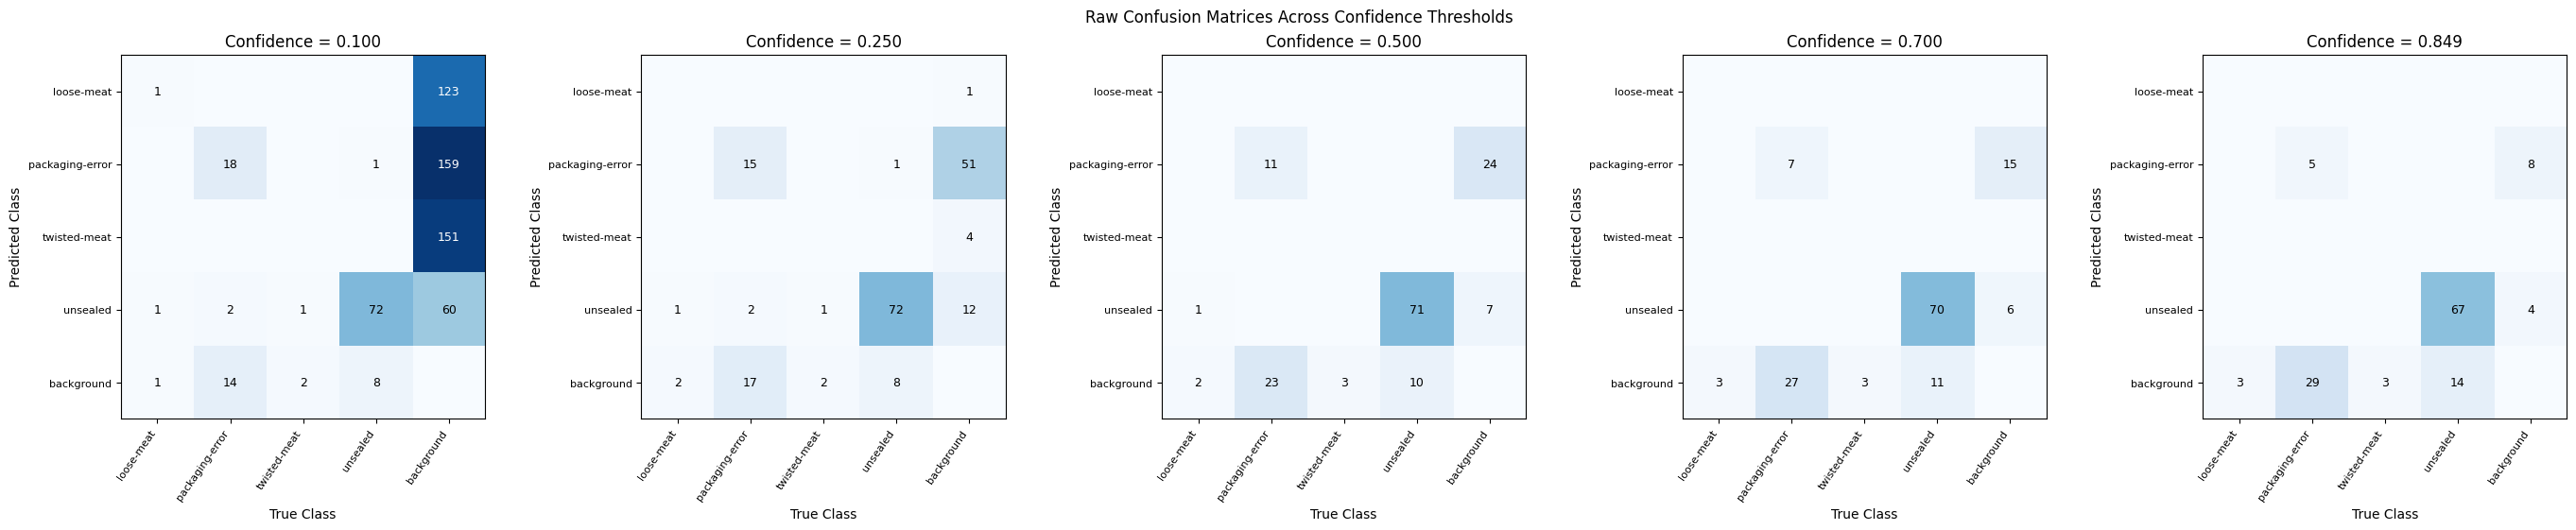

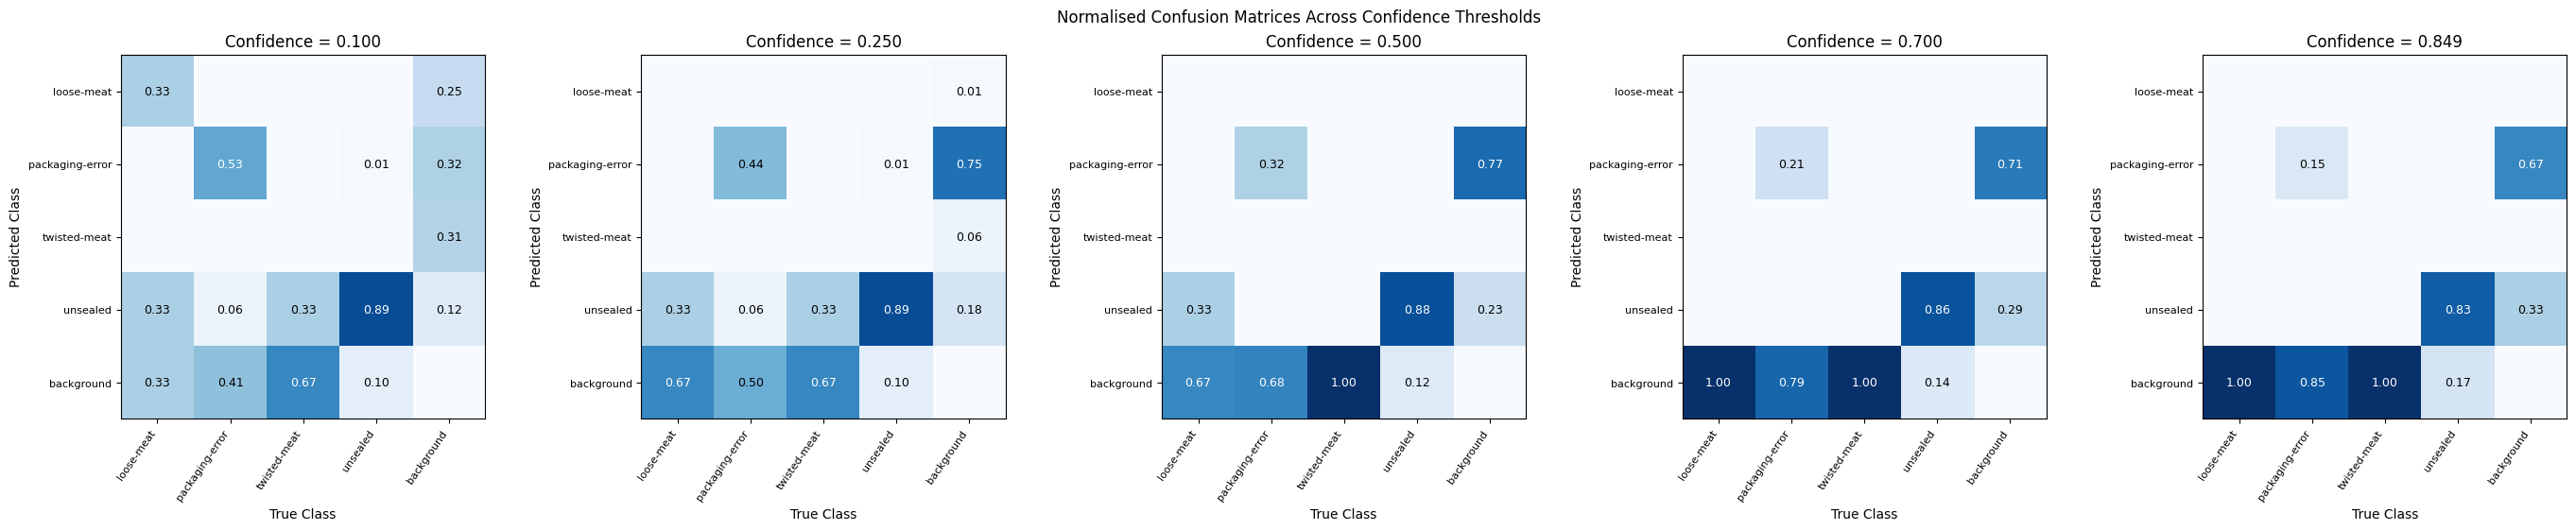

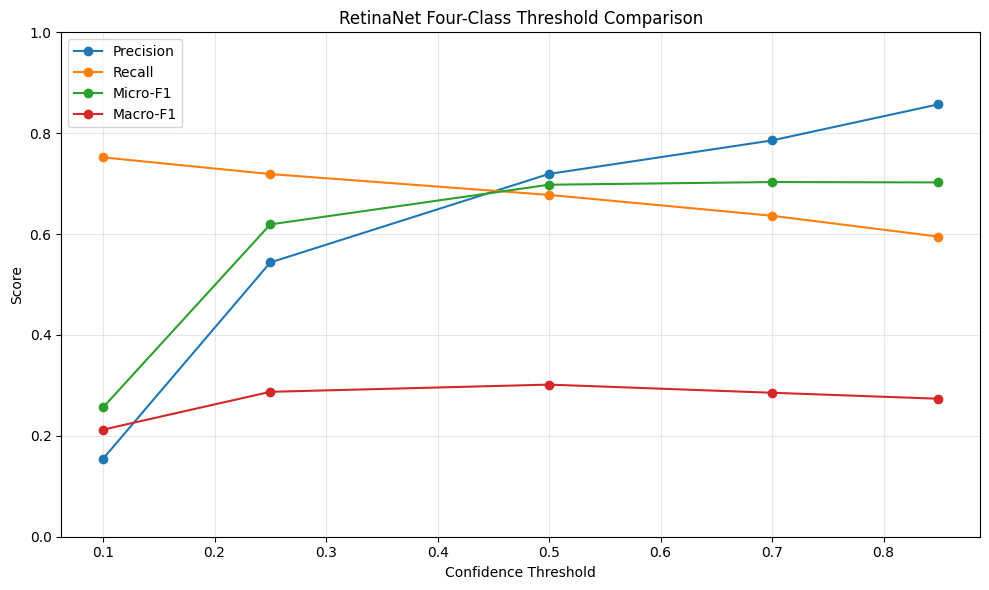


BEST MICRO-F1 AMONG FIVE THRESHOLDS
Threshold: 0.7
Micro-F1: 0.7032


In [9]:

# Evaluate the five original thresholds using shared IoU matching.

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

summary_df, class_df, matrices = evaluate_thresholds(
    predictions=predictions_for_matching,
    targets=targets_all,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    iou_threshold=IOU_THRESHOLD,
    label_offset=1,
)

# Use the original Micro-F1 heading for consistency.
summary_df = summary_df.rename(columns={
    "F1": "Micro-F1",
})

print("FIVE-THRESHOLD RETINANET COMPARISON")

display(summary_df[
    [
        "Threshold",
        "TP",
        "FP",
        "FN",
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
    ]
].round(4))

print("\nCORRECT DETECTIONS BY CLASS")
display(correct_detections_table(class_df))

print("\nPER-CLASS RECALL")
display(per_class_recall_table(class_df).round(4))

# Display all five raw confusion matrices.
raw_figure = plot_confusion_matrices(
    matrices=matrices,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    normalized=False,
)

raw_figure.savefig(
    output_dir / "confusion_matrices_raw.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(raw_figure)

# Display all five normalised confusion matrices.
normalized_figure = plot_confusion_matrices(
    matrices=matrices,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    normalized=True,
)

normalized_figure.savefig(
    output_dir / "confusion_matrices_normalized.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(normalized_figure)

# Preserve the original five-threshold performance graph.
figure = plot_threshold_metrics(
    summary_df,
    metric_columns=[
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
    ],
    title="RetinaNet Four-Class Threshold Comparison",
)

figure.savefig(
    output_dir / "threshold_comparison.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

best_tested = select_best_threshold(
    summary_df,
    metric="Micro-F1",
)

print("\nBEST MICRO-F1 AMONG FIVE THRESHOLDS")
print("Threshold:", float(best_tested["Threshold"]))
print("Micro-F1:", round(float(best_tested["Micro-F1"]), 4))


## 7. Fine Confidence-Threshold Sensitivity

A finer confidence sweep from 0.10 to 0.50, in increments of 0.025, is used to examine the relationship between confidence thresholds, false detections and missed objects.

The threshold maximising validation Micro-F1 is compared with the threshold maximising Macro-F1. Because the dataset is imbalanced, the operating point producing the strongest overall score may not provide the most balanced per-class performance.

The thresholds selected in this analysis are validation operating points and do not use the held-out test set.

FINE CONFIDENCE THRESHOLD SWEEP


,Threshold,TP,FP,FN,Precision,Recall,Micro-F1,Macro-F1
0,0.100,91,498,30,0.1545,0.7521,0.2563,0.2123
1,0.125,90,348,31,0.2055,0.7438,0.3220,0.2429
2,0.150,90,238,31,0.2744,0.7438,0.4009,0.2605
3,0.175,89,160,32,0.3574,0.7355,0.4811,0.2810
4,0.200,88,116,33,0.4314,0.7273,0.5415,0.3142
5,0.225,87,86,34,0.5029,0.7190,0.5918,0.2806
6,0.250,87,73,34,0.5438,0.7190,0.6192,0.2873
7,0.275,86,64,35,0.5733,0.7107,0.6347,0.2867
8,0.300,86,61,35,0.5850,0.7107,0.6418,0.2891
9,0.325,85,57,36,0.5986,0.7025,0.6464,0.2869



BEST MICRO-F1 THRESHOLD
Threshold: 0.500
Precision: 0.7193
Recall: 0.6777
Micro-F1: 0.6979

BEST MACRO-F1 THRESHOLD
Threshold: 0.200
Macro-F1: 0.3142


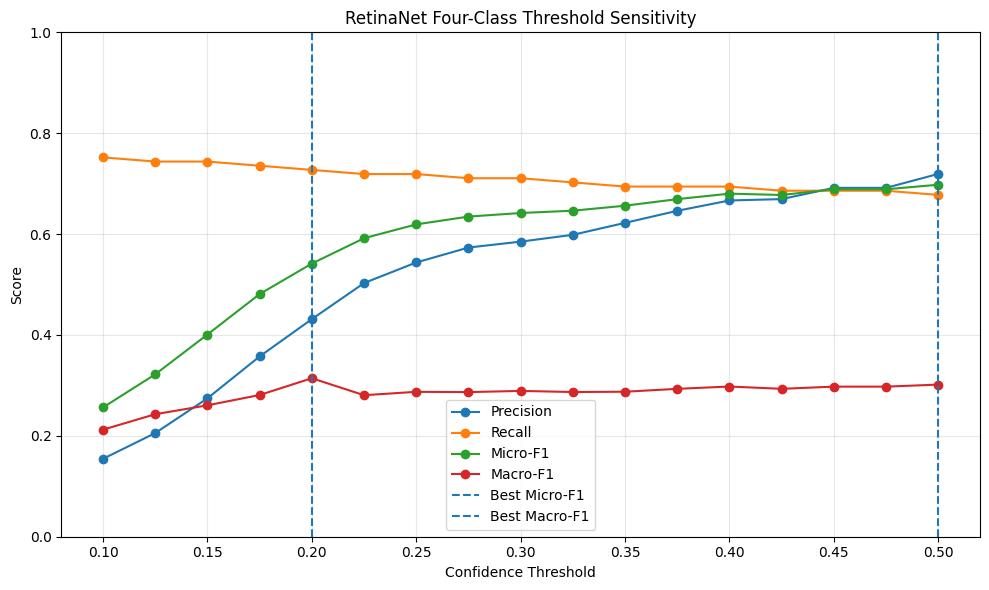

In [10]:

# Evaluate confidence thresholds from 0.10 to 0.50.

FINE_THRESHOLDS = np.round(
    np.arange(0.10, 0.5001, 0.025),
    3,
)

fine_df, fine_class_df, fine_matrices = evaluate_thresholds(
    predictions=predictions_for_matching,
    targets=targets_all,
    thresholds=FINE_THRESHOLDS,
    class_names=CLASS_NAMES,
    iou_threshold=IOU_THRESHOLD,
    label_offset=1,
)

fine_df = fine_df.rename(columns={
    "F1": "Micro-F1",
})

print("FINE CONFIDENCE THRESHOLD SWEEP")
display(fine_df[
    [
        "Threshold",
        "TP",
        "FP",
        "FN",
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
    ]
].round(4))

# Select thresholds independently for micro- and macro-averaged F1.
best_micro = select_best_threshold(
    fine_df,
    metric="Micro-F1",
)

best_macro = select_best_threshold(
    fine_df,
    metric="Macro-F1",
)

print("\nBEST MICRO-F1 THRESHOLD")
print(f"Threshold: {best_micro['Threshold']:.3f}")
print(f"Precision: {best_micro['Precision']:.4f}")
print(f"Recall: {best_micro['Recall']:.4f}")
print(f"Micro-F1: {best_micro['Micro-F1']:.4f}")

print("\nBEST MACRO-F1 THRESHOLD")
print(f"Threshold: {best_macro['Threshold']:.3f}")
print(f"Macro-F1: {best_macro['Macro-F1']:.4f}")

figure = plot_threshold_metrics(
    fine_df,
    metric_columns=[
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
    ],
    title="RetinaNet Four-Class Threshold Sensitivity",
    selected_thresholds={
        "Best Micro-F1": float(best_micro["Threshold"]),
        "Best Macro-F1": float(best_macro["Threshold"]),
    },
)

figure.savefig(
    output_dir / "fine_threshold_sensitivity.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,0.3333,0.5294,0.0,0.8889
0.125,0.3333,0.5000,0.0,0.8889
0.150,0.3333,0.5000,0.0,0.8889
0.175,0.3333,0.4706,0.0,0.8889
0.200,0.3333,0.4412,0.0,0.8889
0.225,0.0000,0.4412,0.0,0.8889
0.250,0.0000,0.4412,0.0,0.8889
0.275,0.0000,0.4118,0.0,0.8889
0.300,0.0000,0.4118,0.0,0.8889


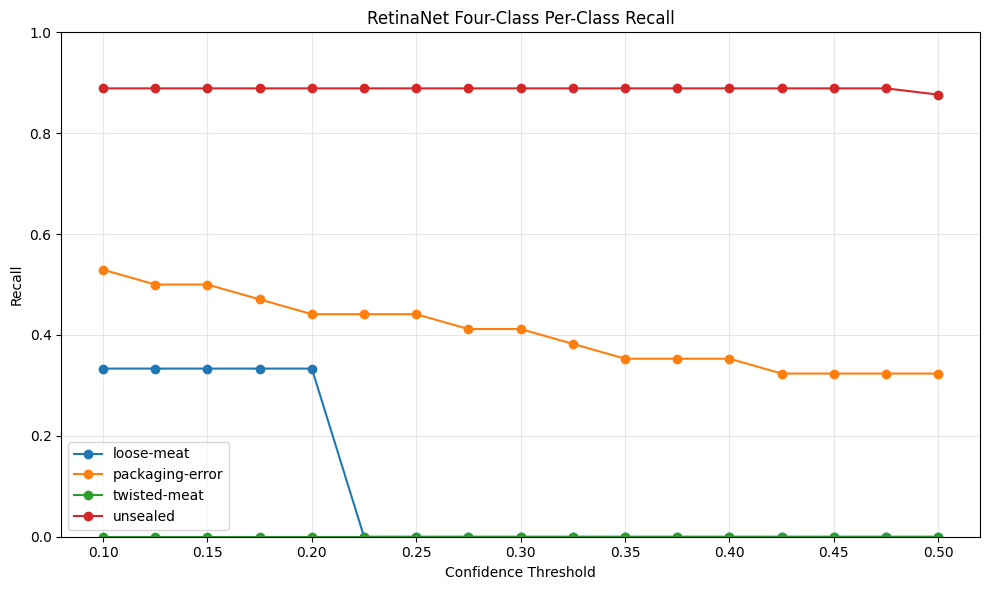


PER-CLASS PERFORMANCE AT SELECTED THRESHOLDS


,Threshold,Class,TP,FP,FN,Precision,Recall,F1
16,0.2,loose-meat,1,7,2,0.1250,0.3333,0.1818
17,0.2,packaging-error,15,70,19,0.1765,0.4412,0.2521
18,0.2,twisted-meat,0,17,3,0.0000,0.0000,0.0000
19,0.2,unsealed,72,22,9,0.7660,0.8889,0.8229
64,0.5,loose-meat,0,0,3,0.0000,0.0000,0.0000
65,0.5,packaging-error,11,24,23,0.3143,0.3235,0.3188
66,0.5,twisted-meat,0,0,3,0.0000,0.0000,0.0000
67,0.5,unsealed,71,8,10,0.8987,0.8765,0.8875



RECALL AT SELECTED THRESHOLDS


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.2,0.3333,0.4412,0.0,0.8889
0.5,0.0000,0.3235,0.0,0.8765


In [11]:

# Plot recall for each defect class across the fine confidence sweep.

recall_table = per_class_recall_table(
    fine_class_df
)

print("PER-CLASS RECALL")
display(recall_table.round(4))

figure = plot_per_class_recall(
    recall_table,
    title="RetinaNet Four-Class Per-Class Recall",
)

figure.savefig(
    output_dir / "per_class_recall.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

selected_thresholds = [
    float(best_micro["Threshold"]),
    float(best_macro["Threshold"]),
]

selected_mask = np.isclose(
    fine_class_df["Threshold"].to_numpy()[:, None],
    selected_thresholds,
).any(axis=1)

print("\nPER-CLASS PERFORMANCE AT SELECTED THRESHOLDS")
display(
    fine_class_df.loc[selected_mask].round(4)
)

print("\nRECALL AT SELECTED THRESHOLDS")
display(
    recall_table.loc[
        recall_table.index.isin(selected_thresholds)
    ].round(4)
)


## 8. Computational Performance

The computational requirements of the saved RetinaNet model are examined using parameter count, checkpoint file size, single-image inference time, approximate throughput and peak GPU memory allocation.

The original experiment's training duration is reported from historical records, not measured again.

Inference timing is performed in the current Colab runtime after model warm-up. Timing and memory results depend on the hardware, runtime environment and inference configuration, so direct model comparisons should use the same evaluation conditions.

In [12]:

# Measure inference performance using the saved RetinaNet checkpoint.

model_parameters = count_parameters(retinanet)

parameter_count = model_parameters["Total Parameters"]

checkpoint_size_mb = (
    best_model_path.stat().st_size / (1024 ** 2)
)

print("Model parameters:", parameter_count)
print("Checkpoint size (MB):", round(checkpoint_size_mb, 2))

sample_image, _ = valid_dataset[0]
sample_image = sample_image.to(device)

retinanet.eval()

# Warm up the detector before measuring steady-state inference.
with torch.inference_mode():
    for _ in range(10):
        _ = retinanet([sample_image])

if device.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

inference_times = []

with torch.inference_mode():
    for _ in range(50):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        _ = retinanet([sample_image])

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed_ms = (
            time.perf_counter() - start_time
        ) * 1000

        inference_times.append(elapsed_ms)

median_inference_ms = float(
    np.median(inference_times)
)

fps = (
    1000.0 / median_inference_ms
    if median_inference_ms > 0
    else np.nan
)

if device.type == "cuda":
    peak_gpu_mb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )
else:
    peak_gpu_mb = np.nan

# This is the historical total recorded in the original notebook.
original_training_seconds = 2321.4753

compute_results = pd.DataFrame([{
    "Model": "RetinaNet ResNet50-FPN V2",
    "Parameters": parameter_count,
    "Checkpoint_MB": checkpoint_size_mb,
    "Inference_ms": median_inference_ms,
    "FPS": fps,
    "Peak_GPU_MB": peak_gpu_mb,
    "Training_seconds": original_training_seconds,
}])

print("\nCOMPUTATIONAL PERFORMANCE")
display(compute_results.round(4))

print("\nHistorical training duration is not a new measurement.")
print("Current inference benchmark device:", device)


Model parameters: 36414865
Checkpoint size (MB): 277.31

COMPUTATIONAL PERFORMANCE


,Model,Parameters,Checkpoint_MB,Inference_ms,FPS,Peak_GPU_MB,Training_seconds
0,RetinaNet ResNet50-FPN V2,36414865,277.308,57.5088,17.3887,211.0532,2321.4753



Historical training duration is not a new measurement.
Current inference benchmark device: cuda


## 9. Findings and Limitations

The saved four-class RetinaNet checkpoint achieved a historical validation mAP@50:95 of approximately 0.2465, with the best model selected at epoch 13 of the 15-epoch training experiment.

The experiment demonstrates differing performance across packaging-defect categories. In particular, class imbalance and the visual characteristics of some defects limit balanced per-class detection performance.

Confidence-threshold analysis demonstrates the trade-off between precision and recall. Both Micro-F1 and Macro-F1 are reported because high overall detection performance does not necessarily imply strong performance across every defect class.

### Limitations

- The four-class dataset is imbalanced, with relatively few loose-meat and twisted-meat validation annotations.
- The evaluation depends on the original dataset annotations, which are treated as reference labels rather than independently verified ground truth.
- Confidence-threshold optimisation is conducted on validation data only.
- Inference-speed comparisons depend on the computational environment and preprocessing settings.
- This notebook loads an existing checkpoint; it does not reproduce the original optimisation process by rerunning training.

The selected checkpoint and validation results will be carried forward to the final three-model comparison.

In [15]:

# Compare all key results against the original executed Notebook 05.

reference_validation = {
    "mAP@50": 0.4098,
    "mAP@50:95": 0.2465,
}

reference_threshold_counts = {
    0.100: (91, 498, 30),
    0.250: (87, 73, 34),
    0.500: (82, 32, 39),
    0.700: (77, 21, 44),
    0.849: (72, 12, 49),
}

print("RETINANET FOUR-CLASS REPRODUCIBILITY CHECKS")

print("\nVALIDATION METRICS")

validation_pass = True

for metric_name, reference in reference_validation.items():
    observed = float(overall_ap_df.iloc[0][metric_name])

    matches = abs(observed - reference) <= 0.005
    validation_pass = validation_pass and matches

    print(
        f"{metric_name}: observed={observed:.4f}, "
        f"reference={reference:.4f}, match={matches}"
    )

print("\nFIVE-THRESHOLD MATCHING")

threshold_pass = True

for threshold, reference_counts in reference_threshold_counts.items():
    row = summary_df.loc[
        np.isclose(summary_df["Threshold"], threshold)
    ].iloc[0]

    observed_counts = (
        int(row["TP"]),
        int(row["FP"]),
        int(row["FN"]),
    )

    matches = observed_counts == reference_counts
    threshold_pass = threshold_pass and matches

    print(
        f"Threshold {threshold:.3f}: "
        f"observed={observed_counts}, "
        f"reference={reference_counts}, "
        f"match={matches}"
    )

print("\nFINE-THRESHOLD SELECTION")

micro_threshold_match = np.isclose(
    float(best_micro["Threshold"]),
    0.500,
)

macro_threshold_match = np.isclose(
    float(best_macro["Threshold"]),
    0.200,
)

micro_score_match = abs(
    float(best_micro["Micro-F1"]) - 0.6979
) <= 0.005

macro_score_match = abs(
    float(best_macro["Macro-F1"]) - 0.3142
) <= 0.005

print("Micro-F1 threshold matches:", micro_threshold_match)
print("Micro-F1 score matches:", micro_score_match)
print("Macro-F1 threshold matches:", macro_threshold_match)
print("Macro-F1 score matches:", macro_score_match)

all_checks_pass = all([
    validation_pass,
    threshold_pass,
    micro_threshold_match,
    macro_threshold_match,
    micro_score_match,
    macro_score_match,
])

print("\nFINAL STATUS")

if all_checks_pass:
    print("PASS")
else:
    print(
        "REVIEW REQUIRED"
    )

print("\nNo model training was performed.")
print("No dataset generation was performed.")
print("The original checkpoint was not modified.")
print("New figures are stored in:", output_dir)


RETINANET FOUR-CLASS REPRODUCIBILITY CHECKS

VALIDATION METRICS
mAP@50: observed=0.4098, reference=0.4098, match=True
mAP@50:95: observed=0.2465, reference=0.2465, match=True

FIVE-THRESHOLD MATCHING
Threshold 0.100: observed=(91, 498, 30), reference=(91, 498, 30), match=True
Threshold 0.250: observed=(87, 73, 34), reference=(87, 73, 34), match=True
Threshold 0.500: observed=(82, 32, 39), reference=(82, 32, 39), match=True
Threshold 0.700: observed=(77, 21, 44), reference=(77, 21, 44), match=True
Threshold 0.849: observed=(72, 12, 49), reference=(72, 12, 49), match=True

FINE-THRESHOLD SELECTION
Micro-F1 threshold matches: True
Micro-F1 score matches: True
Macro-F1 threshold matches: True
Macro-F1 score matches: True

FINAL STATUS
PASS

No model training was performed.
No dataset generation was performed.
The original checkpoint was not modified.
New figures are stored in: /content/notebook05_outputs
